# [2] 다중분류: 태권도 자세 3개(시작/중간/끝)를 MLP로 분류

- 입력: [1] 노트북이 만든 `tk_crops` 사진 (64 x 64로 줄여서 사용)
- 모델: 사진을 한 줄로 펴서(`Flatten`) 넣는 **완전연결 신경망(MLP)**
- 손실함수: `CrossEntropyLoss` (softmax + NLLLoss가 안에 들어 있음)
- 수업: AI개론 9 · 10차시 (FashionMNIST 다중분류)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
# [1] 노트북에서 만든 폴더 (폴더 이름 = 정답)
DATA_DIR = "tk_crops"

transform = transforms.Compose([
    transforms.Resize((64, 64)),                    # 128 → 64 (학습 빠르게)
    transforms.ToTensor(),                          # 0~255 → 0~1, (H,W,C) → (C,H,W)
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # → -1 ~ 1
])

dataset = datasets.ImageFolder(DATA_DIR, transform=transform)
classes = dataset.classes
print("클래스:", dataset.class_to_idx)
print("전체 개수:", len(dataset))

클래스: {'1_start': 0, '2_middle': 1, '3_end': 2}
전체 개수: 1197


In [3]:
# 검증 데이터는 "처음 보는 사람"으로: A040 선수 사진은 전부 val, 나머지는 train
# (같은 사람 사진이 train/val에 섞이면 사람 얼굴·옷으로 외워서 점수가 부풀 수 있음)
VAL_PERSON = "A040"
train_idx = [i for i, (path, _) in enumerate(dataset.samples) if VAL_PERSON not in os.path.basename(path)]
val_idx = [i for i, (path, _) in enumerate(dataset.samples) if VAL_PERSON in os.path.basename(path)]

train_set = Subset(dataset, train_idx)
val_set = Subset(dataset, val_idx)
print("train:", len(train_set), " val:", len(val_set))

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False)

train: 933  val: 264


In [4]:
images, labels = next(iter(train_loader))
print("images:", images.shape, " labels:", labels.shape)    # (32, 3, 64, 64)

plt.figure(figsize=(12, 3))
for i in range(8):
    img = images[i].permute(1, 2, 0) * 0.5 + 0.5      # (C,H,W) → (H,W,C), 정규화 되돌리기
    plt.subplot(1, 8, i + 1)
    plt.imshow(img)
    plt.title(classes[labels[i]], fontsize=9)
    plt.axis("off")
plt.show()

images: torch.Size([32, 3, 64, 64])  labels: torch.Size([32])


## 모델 만들기

In [5]:
model = nn.Sequential(
    nn.Flatten(),                      # (N, 3, 64, 64) → (N, 12288)
    nn.Linear(3 * 64 * 64, 512),
    nn.ReLU(),
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 3),                 # 클래스 3개 → 점수 3개 (softmax 전 logits)
).to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=3, bias=True)
)


## 학습

In [6]:
EPOCHS = 15
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    # ----- 학습 -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()              # 1. 기울기 초기화
        outputs = model(images)            # 2. 순전파
        loss = criterion(outputs, labels)  # 3. 손실 계산
        loss.backward()                    # 4. 역전파
        optimizer.step()                   # 5. 파라미터 갱신

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    train_loss, train_acc = total_loss / total, correct / total

    # ----- 검증 -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():                  # 검증 때는 기울기 계산 안 함
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    val_loss, val_acc = total_loss / total, correct / total

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

Epoch  1 | train loss 1.1218 acc 0.5091 | val loss 0.9305 acc 0.5341
Epoch  2 | train loss 0.6935 acc 0.7063 | val loss 1.0221 acc 0.4924
Epoch  3 | train loss 0.6109 acc 0.7299 | val loss 0.6888 acc 0.7045
Epoch  4 | train loss 0.4653 acc 0.8028 | val loss 0.6368 acc 0.7348
Epoch  5 | train loss 0.4401 acc 0.8135 | val loss 0.7521 acc 0.6705
Epoch  6 | train loss 0.3369 acc 0.8617 | val loss 0.8374 acc 0.6780
Epoch  7 | train loss 0.2960 acc 0.8778 | val loss 0.7262 acc 0.7121
Epoch  8 | train loss 0.2791 acc 0.8971 | val loss 0.6112 acc 0.7689
Epoch  9 | train loss 0.2078 acc 0.9228 | val loss 0.7164 acc 0.7386
Epoch 10 | train loss 0.1961 acc 0.9239 | val loss 0.9535 acc 0.6629
Epoch 11 | train loss 0.1820 acc 0.9335 | val loss 0.6858 acc 0.7614
Epoch 12 | train loss 0.1798 acc 0.9314 | val loss 0.5865 acc 0.7841
Epoch 13 | train loss 0.1632 acc 0.9303 | val loss 1.0316 acc 0.6288
Epoch 14 | train loss 0.2731 acc 0.8896 | val loss 0.6157 acc 0.7424
Epoch 15 | train loss 0.1221 acc 0

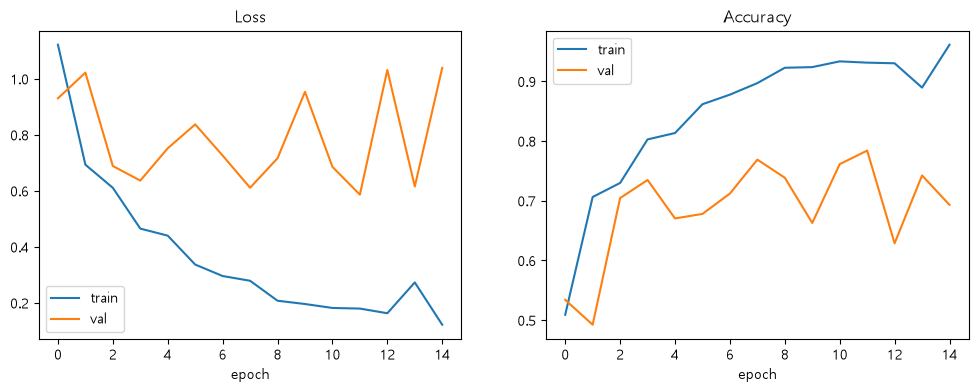

In [7]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="train"); plt.plot(history["val_acc"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()
plt.show()

## 평가

[[70 18  0]
 [26 62  0]
 [26 11 51]]


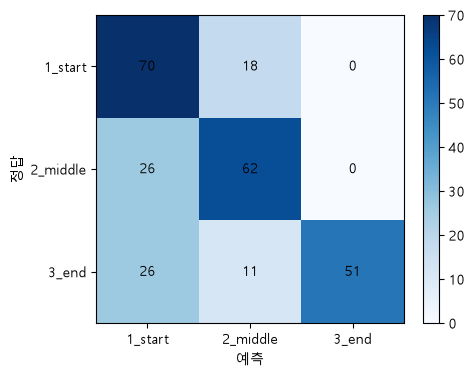

1_start    정확도: 0.80
2_middle   정확도: 0.70
3_end      정확도: 0.58


In [8]:
# 혼동행렬: 행 = 정답, 열 = 예측
all_labels, all_preds = [], []
model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images.to(device))
        all_preds += outputs.argmax(1).cpu().tolist()
        all_labels += labels.tolist()

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(all_labels, all_preds):
    cm[t, p] += 1
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
plt.xlabel("예측"); plt.ylabel("정답")
for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(); plt.show()

for i, c in enumerate(classes):
    print(f"{c:10s} 정확도: {cm[i, i] / cm[i].sum():.2f}")

In [9]:
# val 사진 8장 예측해보기 (빨간 제목 = 틀림)
images, labels = next(iter(val_loader))
model.eval()
with torch.no_grad():
    probs = torch.softmax(model(images.to(device)), dim=1).cpu()   # 점수 → 확률
preds = probs.argmax(1)

plt.figure(figsize=(14, 3.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i].permute(1, 2, 0) * 0.5 + 0.5)
    color = "black" if preds[i] == labels[i] else "red"
    plt.title(f"정답 {classes[labels[i]]}\n예측 {classes[preds[i]]}\n{probs[i, preds[i]]:.0%}", fontsize=8, color=color)
    plt.axis("off")
plt.show()